<a href="https://colab.research.google.com/github/alina012345/student-dropout-ml-project/blob/main/01_data_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Milestone 2: Data and Baseline Checkpoint



In [1]:


import pandas as pd
import zipfile
from pathlib import Path

zip_path = Path("predict+students+dropout+and+academic+success.zip")

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("data.csv") as f:
        df = pd.read_csv(f, sep=";")

print("Dataset shape:", df.shape)

display(df.head())




Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Data Audit

In [2]:
df.info()

print("Missing values:")
print(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Target distribution:")
print(df["Target"].value_counts())

print("Target distribution (%):")
print((df["Target"].value_counts(normalize=True) * 100).round(1))

display(df.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance\t,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nacionality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


The dataset contains 4424 records in total and 31 columns including target variables.

No missing values, no duplicate rows.

For datatypes there are 7 float columns, 29 integer columns, 1 object column.

The target classess (Graduaate, Dropout, Entrolled) are imbalanced.
- Graduate: 2209 (49.9%)
- Dropout: 1421 (32.1%)
- Entrolled: 794 (17.9%)

Outlier investigation

count    4424.000000
mean       23.265145
std         7.587816
min        17.000000
25%        19.000000
50%        20.000000
75%        25.000000
max        70.000000
Name: Age at enrollment, dtype: float64


<Axes: >

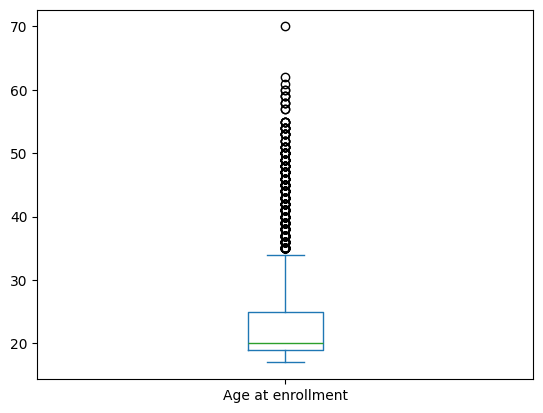

In [3]:
print(df["Age at enrollment"].describe())

df["Age at enrollment"].plot.box()

In [4]:
Q1 = df["Age at enrollment"].quantile(0.25)
Q3 = df["Age at enrollment"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print("Upper bound:", upper_bound)
print("Potential outliers:",
      (df["Age at enrollment"] > upper_bound).sum())


Upper bound: 34.0
Potential outliers: 441


The age of entrollment ranges from 17 to 70 years. The median is 20.

The boxplot shows potential outliers above 34 years.

Based on the iqr method, 441 records were identified as pontential outliers.

These values may represent older students entrolling at university rather than data errors.

No records were removed at this stage.

In [5]:
columns = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)"
]

display(df[columns].describe().loc[["min", "max"]].T)

,min,max
Previous qualification (grade),95.0,190.0
Admission grade,95.0,190.0
Curricular units 1st sem (enrolled),0.0,26.0
Curricular units 1st sem (approved),0.0,26.0
Curricular units 2nd sem (enrolled),0.0,23.0
Curricular units 2nd sem (approved),0.0,20.0


Previous qualification and admission grades range from 95 to 190.

The number of entrolled and approved curricular units ranges from 0 to 26 in the first semester; from 0 to 23 and 0 to 20 in the secind semestr.

No negative were found in checked columns.
No obvious invalis values were identifies form these ranges

In [6]:
for sem in ["1st", "2nd"]:
    enrolled = df[f"Curricular units {sem} sem (enrolled)"]
    approved = df[f"Curricular units {sem} sem (approved)"]

    print(f"{sem} semester inconsistencies:",
          (approved > enrolled).sum())


1st semester inconsistencies: 0
2nd semester inconsistencies: 0


No inconsistencies were found between enrolled and approved curricular units in either semester

Preprocessing

Feature types:

In [7]:
X = df.drop(columns=["Target"])
y = df["Target"]

print(X.nunique().sort_values())

Gender                                              2
International                                       2
Scholarship holder                                  2
Tuition fees up to date                             2
Daytime/evening attendance\t                        2
Debtor                                              2
Educational special needs                           2
Displaced                                           2
Marital status                                      6
Application order                                   8
Inflation rate                                      9
GDP                                                10
Unemployment rate                                  10
Curricular units 2nd sem (without evaluations)     10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

Categorical and numerical features

In [8]:
categorical_cols = []

for col in X.columns:
    if col.startswith("Daytime/evening attendance"):
        categorical_cols.append(col)

categorical_cols += [
    "Displaced",
    "Debtor",
    "Educational special needs",
    "International",
    "Scholarship holder",
    "Gender",
    "Tuition fees up to date",
    "Marital status",
    "Previous qualification",
    "Course",
    "Application mode",
    "Nacionality",
    "Mother's qualification",
    "Mother's occupation",
    "Father's qualification",
    "Father's occupation"
]

numerical_cols = [
    col for col in X.columns if col not in categorical_cols
]

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))
print("Total features:", len(X.columns))




Categorical features: 17
Numerical features: 19
Total features: 36


The 36 input features were divided into 17 categorical and 19 numerical features based on their meaning.

Train/Test split

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (3539, 36)
Test set: (885, 36)


The dataset was split into 80% of training data and 20% of testing data.
Stratification was used to preserve the target class proportion, as the classes are imbalanced.
A random state of 42 was used to make the split reproducible.

Preprocessing pipeline

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Application order',
                                  'Previous qualification (grade)',
                                  'Admission grade', 'Age at enrollment',
                                  'Curricular units 1st sem (credited)',
                                  'Curricular units 1st sem (enrolled)',
                                  'Curricular units 1st sem (evaluations)',
                                  'Curricular units 1st sem (approved)',
                                  'Curricular units 1st sem (grade)',
                                  'Curricular units 1st sem (without '
                                  'evalua...
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Daytime/evening attendance\t', 'Displaced',
                                  'Debtor', 'Educational special needs',
                                

In [11]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Training set:", X_train_prepared.shape)
print("Test set:", X_test_prepared.shape)

Training set: (3539, 244)
Test set: (885, 244)


Numerical features were scaled using StandardScaler, and categorical were encoded using OneHotEncoder.
After preprocessing datasets contain 244 features.

Baseline model

In [12]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)

print("Baseline predictions:")
print(y_pred[:10])

Baseline predictions:
['Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


Baseline evaluation

In [13]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1-score:", f1_score(y_test, y_pred, average="macro"))

print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.4994350282485876
Macro F1-score: 0.22205476011052497
Classification report:
              precision    recall  f1-score   support

     Dropout       0.00      0.00      0.00       284
    Enrolled       0.00      0.00      0.00       159
    Graduate       0.50      1.00      0.67       442

    accuracy                           0.50       885
   macro avg       0.17      0.33      0.22       885
weighted avg       0.25      0.50      0.33       885

Confusion matrix:
[[  0   0 284]
 [  0   0 159]
 [  0   0 442]]


The baseline model achived 49.94 accuracy and a macro f1 score of 0.22.

The model predicted graduate for every student because it was the most common class in the training set.

The confusion matrix shows that all graduate were correct, but it faild to predict dropout and entrolled students correctly.
